### Import basic Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("C:\Auspify Technologies ML intern\Data\Dataset.csv")
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
print("Shape", df.shape)
print("-*" * 50)
print("Columns:", df.columns)
print("-*" * 50)
df.info()
print("-*" * 50)
print("Duplicates :", df.duplicated().sum())

Shape (8790, 10)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Columns: Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='object')
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: 

### Exploratory Data Analysis (EDA)

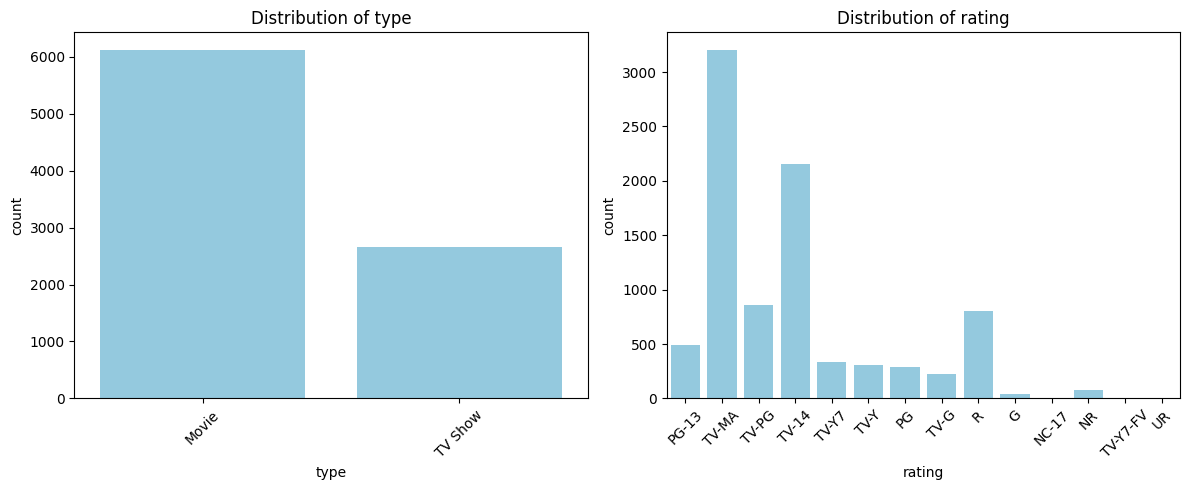

In [4]:

cols = ['type', 'rating']

plt.figure(figsize=(12, 5))

for inx, col in enumerate(cols):
    plt.subplot(1, 2, inx + 1)

    sns.countplot(data=df, x=col, color='skyblue')

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The audience rating categories are highly imbalanced, with a small number of rating classes representing most of the dataset. Therefore, accuracy alone may not provide a complete evaluation of model performance.

In [5]:
# Top 5 countries
print(df['country'].value_counts().head())

# Total countries
total = len(df['country'].unique())
print(f"\n Total unique countries: {total}")

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64

 Total unique countries: 86


### Preprocessing Data

In [6]:
dataset = df[['type', 'country', 'date_added',
         'release_year', 'rating', 'duration', 'listed_in']]

dataset.head(3)

,type,country,date_added,release_year,rating,duration,listed_in
0,Movie,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,TV Show,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,TV Show,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"


In [7]:
# Separating year, month, day from  date_added

print("Before converting")
print('Data type of date_added:', dataset['date_added'].dtypes)

dataset['date_added'] =pd.to_datetime(dataset['date_added'])

print('\n After converting')
print('Data type of date_added:', dataset['date_added'].dtypes)

dataset['year_added'] = dataset['date_added'].dt.year
dataset['month_added'] = dataset['date_added'].dt.month
dataset['day_added'] = dataset['date_added'].dt.day

# Remove the main date_added feature
dataset.drop(columns=['date_added'], inplace=True)


Before converting
Data type of date_added: object

 After converting
Data type of date_added: datetime64[ns]


In [8]:
# seperate duration into value and unit

dataset['duration_value'] = dataset['duration'].str.extract(r'(\d+)').astype(float)
dataset['duration_unit'] = dataset['duration'].str.extract(r'([A-Za-z]+)')

dataset.drop(columns=['duration'], inplace=True)


### Feature Selection

After training the initial classification models, I evaluated the contribution of the available features. The features `year_added`, `month_added`, `day_added`, `duration_value`, and `duration_unit` did not provide a significant improvement in model performance.

Therefore, to keep the model simpler and avoid using features that provide limited predictive value, I decided to remove these features from the final training dataset.

The final model uses the following four main features:

* `release_year`
* `type`
* `country`
* `listed_in`


In [9]:
# Preprocessing the training data
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer

num_col = [
    'release_year',
]

cat_col = [
    'type',
    'country',
    'listed_in',
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_col),
        ('cat', OneHotEncoder(
            drop='first',
            handle_unknown='ignore'
        ), cat_col)
    ]
)

# Encode target
le = LabelEncoder()
dataset['rating'] = le.fit_transform(dataset['rating'])


In [10]:
# Train Test split
from sklearn.model_selection import train_test_split

X = dataset[['release_year',
    'type',
    'country',
    'listed_in',
]]
y = dataset['rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("X-train Shape:", X_train.shape)
print("X-test Shape:", X_test.shape)
print("y-train Shape:", y_train.shape)
print("y-test Shape:", y_test.shape)

X-train Shape: (7032, 4)
X-test Shape: (1758, 4)
y-train Shape: (7032,)
y-test Shape: (1758,)


### Training Classification Model

In [11]:
# Model selection
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix


models = {
    'LR': LogisticRegression(
        max_iter=1000
    ),

    'DT': DecisionTreeClassifier(
        random_state=42,
        max_depth=7
    ),

    'RFC': RandomForestClassifier(
        random_state=42,
        n_estimators=200,
        max_depth=7
    ),

    'XBC': XGBClassifier(
        random_state=42,
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        eval_metric='logloss'
    )
}

# Preprocessing the data
X_train_tf = preprocessor.fit_transform(X_train)
X_test_tf = preprocessor.transform(X_test)


# Model Training
for name, model in models.items():
    print(f"{'-*'*20} {name} {'-*'*20}")
    model.fit(X_train_tf, y_train)
    
    y_pred = model.predict(X_test_tf)
    print("classification report:", classification_report(y_test, y_pred))
    print('confusion matrix:', confusion_matrix(y_test, y_pred))
    print(f"Training Accuracy: {model.score(X_train_tf, y_train)}")
    print(f"Testing Accuracy: {model.score(X_test_tf, y_test)}")


-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-* LR -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
classification report:               precision    recall  f1-score   support

           0       1.00      0.12      0.22         8
           1       0.00      0.00      0.00         1
           2       0.00      0.00      0.00        16
           3       0.44      0.40      0.42        57
           4       0.47      0.43      0.45        98
           5       0.45      0.52      0.48       160
           6       0.51      0.49      0.50       431
           7       0.00      0.00      0.00        44
           8       0.56      0.73      0.64       641
           9       0.34      0.12      0.18       172
          10       0.53      0.57      0.55        61
          11       0.53      0.46      0.49        67
          12       0.00      0.00      0.00         1
          13       0.00      0.00      0.00         1

    accuracy                           0.52      1758
   macro avg       0.35   

### Optimizing Model Performace

In [12]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 7, 10],
    'learning_rate': [0.1, 0.2, 0.5]
}

grid_search = GridSearchCV(
    XGBClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1
)

grid_search.fit(X_train_tf, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.5, 'max_depth': 7, 'n_estimators': 200}
Best CV Score: 0.5058445645662301


### Evaluate The Final Model

In [13]:
final_model = XGBClassifier(
    learning_rate = 0.5 ,
    max_depth = 7,
    n_estimators = 200,
    random_state = 42
)

final_model.fit(X_train_tf, y_train)

y_pred = final_model.predict(X_test_tf)
print("classification report:", classification_report(y_test, y_pred))
print('confusion matrix:', confusion_matrix(y_test, y_pred))

classification report:               precision    recall  f1-score   support

           0       0.22      0.25      0.24         8
           1       0.00      0.00      0.00         1
           2       0.00      0.00      0.00        16
           3       0.62      0.35      0.45        57
           4       0.40      0.36      0.38        98
           5       0.47      0.46      0.47       160
           6       0.49      0.47      0.48       431
           7       0.32      0.16      0.21        44
           8       0.60      0.73      0.66       641
           9       0.33      0.22      0.26       172
          10       0.53      0.57      0.55        61
          11       0.54      0.51      0.52        67
          12       0.00      0.00      0.00         1
          13       0.00      0.00      0.00         1

    accuracy                           0.52      1758
   macro avg       0.32      0.29      0.30      1758
weighted avg       0.50      0.52      0.51      1758

co

### Conclusion:
 The classification models were able to predict the most common rating categories reasonably well, but performance on minority classes remained limited. The dataset showed substantial class imbalance, which affected the overall classification performance. Hyperparameter tuning was performed, but it did not result in a significant improvement. Therefore, the final model represents a reasonable baseline given the available data, while further improvement would likely require addressing the class imbalance and obtaining more samples for underrepresented rating categories.